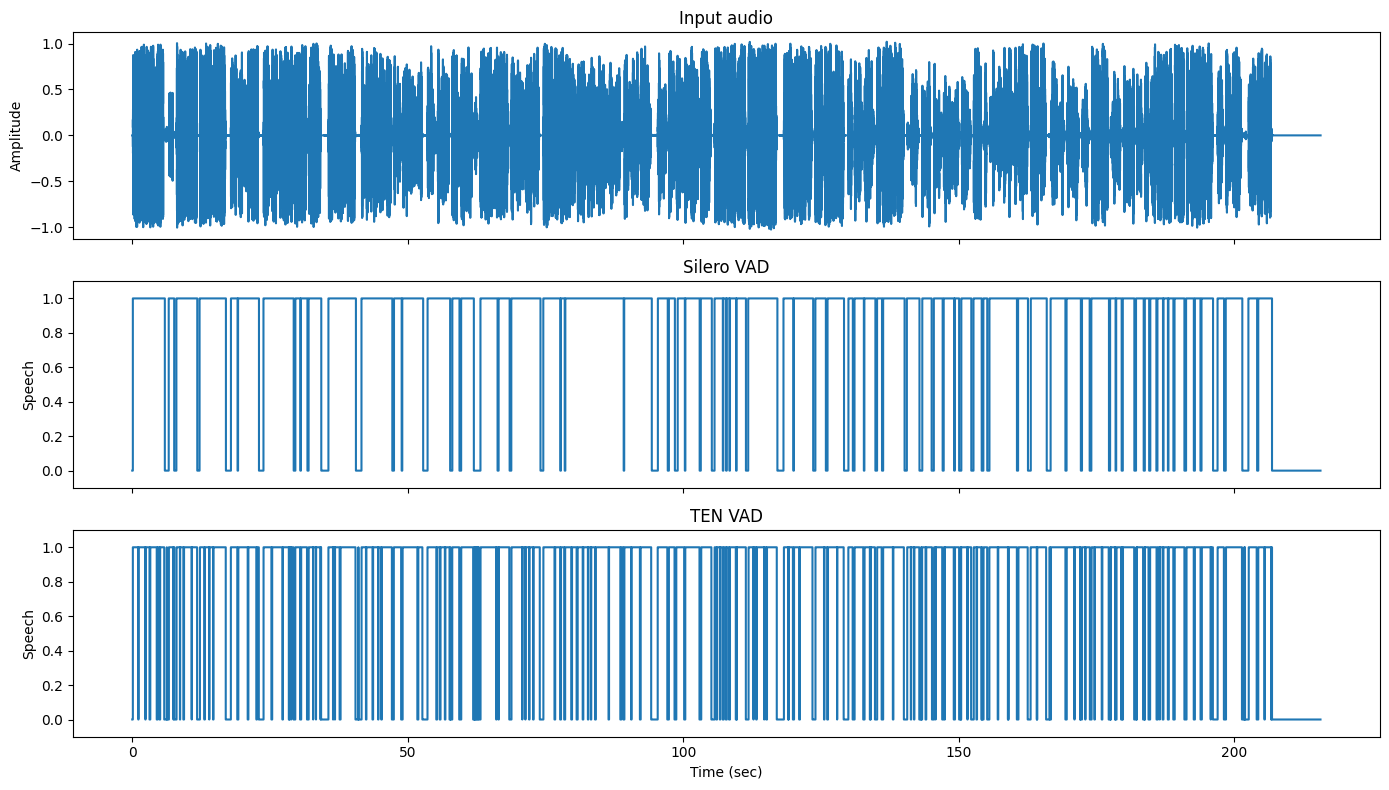

In [ ]:
# ==============================
# Импорты
# ==============================

import numpy as np
import librosa
import matplotlib.pyplot as plt
from ten_vad import TenVad
from silero_vad import load_silero_vad, get_speech_timestamps
import torch

# ==============================
# 1. Загрузка и подготовка аудио
# ==============================

# Загружаем и ресемплируем в 16kHz mono
audio_float, sr = librosa.load(
    "../../data/audio-test.wav",
    sr=16000,
    mono=True
)

# TEN требует int16
audio_int16 = (audio_float * 32767).astype(np.int16)
audio_int16 = np.ascontiguousarray(audio_int16)

# ==============================
# 2. TEN VAD (frame-level)
# ==============================

hop_size = 256
vad = TenVad(hop_size=hop_size, threshold=0.5)

ten_probs = []
ten_flags = []

for i in range(0, len(audio_int16) - hop_size + 1, hop_size):
    frame = audio_int16[i:i+hop_size]
    prob, flag = vad.process(frame)
    ten_probs.append(prob)
    ten_flags.append(flag)

ten_probs = np.array(ten_probs)
ten_flags = np.array(ten_flags)

# ==============================
# 3. Silero VAD (segment-level)
# ==============================

model = load_silero_vad()

# Silero работает с float32 torch tensor
silero_input = torch.from_numpy(audio_float).float()

silero_segments = get_speech_timestamps(
    silero_input,
    model,
    return_seconds=True
)

# ==============================
# 4. Silero → frame-level mask
# ==============================

silero_mask = np.zeros(len(audio_float))

for seg in silero_segments:
    start_sample = int(seg['start'] * sr)
    end_sample = int(seg['end'] * sr)
    silero_mask[start_sample:end_sample] = 1

silero_frame_mask = []

for i in range(0, len(audio_float) - hop_size + 1, hop_size):
    frame = silero_mask[i:i+hop_size]
    silero_frame_mask.append(int(np.mean(frame) > 0.5))

silero_frame_mask = np.array(silero_frame_mask)

# ==============================
# 5. Синхронизация длины
# ==============================

min_len = min(len(silero_frame_mask), len(ten_flags))
silero_frame_mask = silero_frame_mask[:min_len]
ten_flags = ten_flags[:min_len]
ten_probs = ten_probs[:min_len]

frame_duration = hop_size / sr
time_frames = np.arange(min_len) * frame_duration
time_audio = np.arange(len(audio_float)) / sr

# ==============================
# 6. Визуализация
# ==============================

fig, axes = plt.subplots(3, 1, figsize=(14, 8), sharex=True)

# Waveform
axes[0].plot(time_audio, audio_float)
axes[0].set_title("Input audio")
axes[0].set_ylabel("Amplitude")

# Silero
axes[1].step(time_frames, silero_frame_mask, where="post")
axes[1].set_title("Silero VAD")
axes[1].set_ylim(-0.1, 1.1)
axes[1].set_ylabel("Speech")

# TEN
axes[2].step(time_frames, ten_flags, where="post")
axes[2].set_title("TEN VAD")
axes[2].set_ylim(-0.1, 1.1)
axes[2].set_ylabel("Speech")
axes[2].set_xlabel("Time (sec)")

plt.tight_layout()
plt.show()

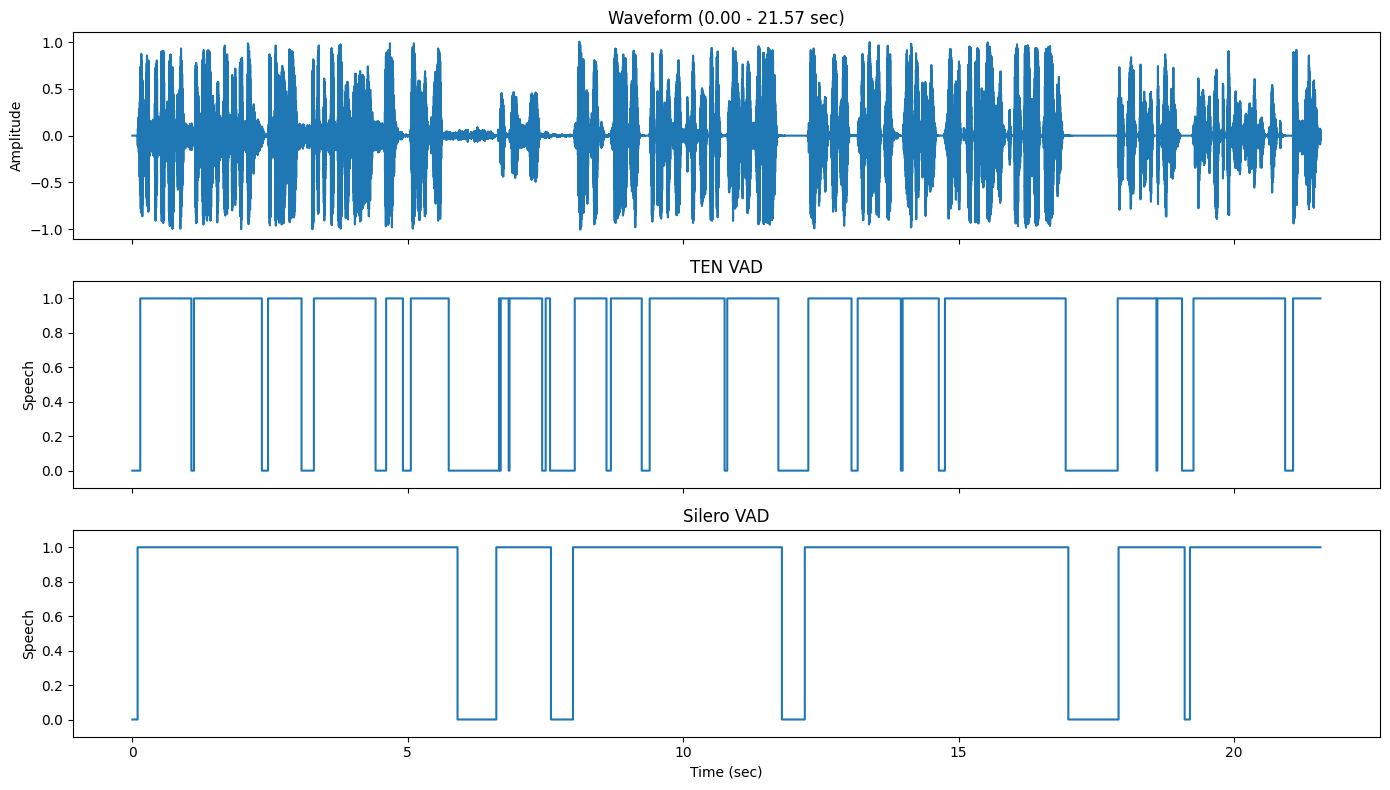

In [20]:
import numpy as np
import librosa
import matplotlib.pyplot as plt
from ten_vad import TenVad
from silero_vad import load_silero_vad, get_speech_timestamps
import torch

# =====================================================
# ПАРАМЕТРЫ УПРАВЛЕНИЯ
# =====================================================

num_parts = 20       # на сколько частей делим весь файл
part_index = 0       # какую часть отображать (0..9)       # если нужен весь файл

hop_size = 256

# =====================================================
# 1. Загрузка аудио
# =====================================================

audio_float, sr = librosa.load(
    "../data/audio-test.wav",
    sr=16000,
    mono=True
)

audio_int16 = (audio_float * 32767).astype(np.int16)
audio_int16 = np.ascontiguousarray(audio_int16)

# =====================================================
# 2. TEN VAD
# =====================================================

vad = TenVad(hop_size=hop_size, threshold=0.6)

ten_flags = []

for i in range(0, len(audio_int16) - hop_size + 1, hop_size):
    frame = audio_int16[i:i+hop_size]
    _, flag = vad.process(frame)
    ten_flags.append(flag)

ten_flags = np.array(ten_flags)

# =====================================================
# 3. Silero VAD
# =====================================================

model = load_silero_vad()
silero_input = torch.from_numpy(audio_float).float()

silero_segments = get_speech_timestamps(
    silero_input,
    model,
    return_seconds=True
)

# Silero → sample mask
silero_mask = np.zeros(len(audio_float))

for seg in silero_segments:
    start_sample = int(seg['start'] * sr)
    end_sample = int(seg['end'] * sr)
    silero_mask[start_sample:end_sample] = 1

# sample → frame mask
silero_frame_mask = []

for i in range(0, len(audio_float) - hop_size + 1, hop_size):
    frame = silero_mask[i:i+hop_size]
    silero_frame_mask.append(int(np.mean(frame) > 0.5))

silero_frame_mask = np.array(silero_frame_mask)

# =====================================================
# 4. Синхронизация
# =====================================================

min_len = min(len(silero_frame_mask), len(ten_flags))
silero_frame_mask = silero_frame_mask[:min_len]
ten_flags = ten_flags[:min_len]

frame_duration = hop_size / sr
time_frames = np.arange(min_len) * frame_duration
time_audio = np.arange(len(audio_float)) / sr

# =====================================================
# 5. Делим весь файл на num_parts и выбираем одну часть
# =====================================================

num_parts = 10
part_index = 0  # от 0 до 9

total_duration = time_audio[-1]
part_duration = total_duration / num_parts

start_sec = part_index * part_duration
end_sec = start_sec + part_duration

# маски
audio_mask = (time_audio >= start_sec) & (time_audio <= end_sec)
frame_mask = (time_frames >= start_sec) & (time_frames <= end_sec)

audio_view = audio_float[audio_mask]
time_audio_view = time_audio[audio_mask]

ten_view = ten_flags[frame_mask]
silero_view = silero_frame_mask[frame_mask]
time_frames_view = time_frames[frame_mask]

# =====================================================
# 6. Построение (3 вертикальных графика)
# =====================================================

fig, axes = plt.subplots(3, 1, figsize=(14, 8), sharex=True)

# Waveform
axes[0].plot(time_audio_view, audio_view)
axes[0].set_title(f"Waveform ({start_sec:.2f} - {end_sec:.2f} sec)")
axes[0].set_ylabel("Amplitude")

# TEN VAD
axes[1].step(time_frames_view, ten_view, where="post")
axes[1].set_title("TEN VAD")
axes[1].set_ylim(-0.1, 1.1)
axes[1].set_ylabel("Speech")

# Silero VAD
axes[2].step(time_frames_view, silero_view, where="post")
axes[2].set_title("Silero VAD")
axes[2].set_ylim(-0.1, 1.1)
axes[2].set_ylabel("Speech")
axes[2].set_xlabel("Time (sec)")

plt.tight_layout()
plt.show()